# Modularity on the Karate Club Graph
**DSC212 – Graph Theory Module · Research Assignment**

This notebook implements the **spectral modularity method from scratch** (NumPy + NetworkX only) on Zachary's Karate Club network and extends it to many communities by **recursive bisection**. It then tracks how four node-level network metrics evolve as the communities are discovered.

**Contents**
1. Data: the Karate Club graph and its ground-truth split
2. The modularity matrix $B$
3. Spectral bipartition (leading eigenvector) and the eigenvalue stopping rule
4. Recursive bisection → multiple communities
5. Visualization of the graph after every split
6. Node metrics after every split (degree, betweenness, closeness, clustering)
7. Evolution of each metric across iterations
8. Discussion
9. Sanity checks


In [1]:
import os
import numpy as np
import networkx as nx
from networkx.algorithms import community as nx_community
import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)      # every figure is also saved here (used by the README)
SEED = 42                                 # fixed seed -> identical graph layout in every figure
plt.rcParams.update({"figure.dpi": 110})

## 1. Data: the Karate Club graph

NetworkX ships Zachary's network. It has $n=34$ members (nodes) and $m=78$ friendship ties (edges).
Node `i` here is member `i+1` in Zachary's paper: **node 0 is the instructor "Mr. Hi"** and **node 33 is the club president ("Officer")**.
Each node stores the faction it joined after the split in its `club` attribute. We keep this **only as ground truth for comparison**; the algorithm never sees it.

> **Note.** Recent NetworkX versions attach a `weight` attribute to the edges of this graph. The handout works with a *binary* adjacency matrix, so everywhere below we explicitly ask for `weight=None`.

In [2]:
G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = list(G.nodes())                                   # 0, 1, ..., 33
club = np.array([G.nodes[v]["club"] for v in nodes])      # ground truth: 'Mr. Hi' or 'Officer'

print(f"n = {n} nodes, m = {m} edges")
print("Ground-truth faction sizes:", {str(c): int((club == c).sum()) for c in np.unique(club)})

n = 34 nodes, m = 78 edges
Ground-truth faction sizes: {'Mr. Hi': 17, 'Officer': 17}


### A fixed layout and a drawing helper
The spring layout is computed **once** (fixed seed) and reused for every figure, so nodes never move and only the colours change.
Circles = members of Mr. Hi's faction, squares = members of the Officer's faction (ground truth). Fill colour = community found by the algorithm.

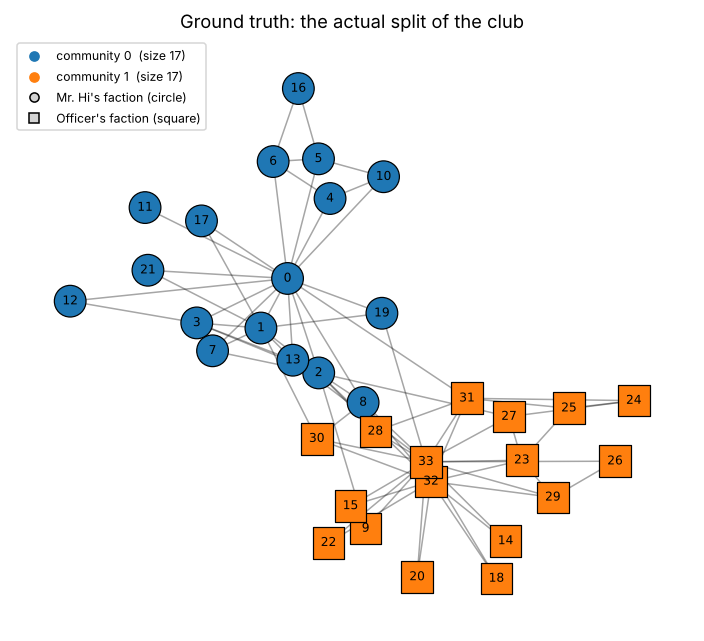

In [3]:
pos = nx.spring_layout(G, seed=SEED)       # computed once, reused everywhere
PALETTE = plt.get_cmap("tab10").colors

def draw_partition(labels, title, ax):
    '''Draw G with one colour per community (labels[v] = community id of node v).'''
    labels = np.asarray(labels)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=1.0)
    for shape, faction in [("o", "Mr. Hi"), ("s", "Officer")]:
        members = [v for v in nodes if club[v] == faction]
        nx.draw_networkx_nodes(G, pos, nodelist=members, node_shape=shape, node_size=430,
                               node_color=[PALETTE[labels[v] % 10] for v in members],
                               edgecolors="black", linewidths=0.8, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)          # node ID labels
    handles = [plt.Line2D([], [], marker="o", ls="", color=PALETTE[c % 10],
                          label=f"community {c}  (size {(labels == c).sum()})")
               for c in np.unique(labels)]
    handles += [plt.Line2D([], [], marker="o", ls="", color="lightgray", markeredgecolor="black",
                           label="Mr. Hi's faction (circle)"),
                plt.Line2D([], [], marker="s", ls="", color="lightgray", markeredgecolor="black",
                           label="Officer's faction (square)")]
    ax.legend(handles=handles, loc="upper left", fontsize=8)
    ax.set_title(title)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(8, 7))
draw_partition((club == "Officer").astype(int), "Ground truth: the actual split of the club", ax)
plt.savefig("assets/00_ground_truth.png", bbox_inches="tight")
plt.show()

## 2. The modularity matrix $B$

With adjacency matrix $A$, degree vector $\mathbf{k}$ and $2m=\sum_i k_i$:

$$B = A - \frac{\mathbf{k}\mathbf{k}^\top}{2m}, \qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.$$

The second term is the expected number of edges between $i$ and $j$ in the degree-preserving random (stub-matching) null model. For a $\pm1$ label vector $\mathbf{s}$, the modularity is $Q=\frac{1}{4m}\,\mathbf{s}^\top B\,\mathbf{s}$.

We also verify the facts proved in Section 5 of the handout: $B$ is real symmetric (Prop. 1), $B\mathbf{1}=\mathbf{0}$ (Prop. 2), and the trivial one-community partition has $Q=0$ (Cor. 1).

In [4]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # binary adjacency matrix
k = A.sum(axis=1)                                       # degree vector
B = A - np.outer(k, k) / (2 * m)                        # modularity matrix

ones = np.ones(n)
print("A symmetric, entries in {0,1}      :", np.allclose(A, A.T) and set(np.unique(A)) <= {0.0, 1.0})
print("sum of degrees = 2m                :", int(k.sum()), "=", 2 * m)
print("B symmetric (Proposition 1)        :", np.allclose(B, B.T))
print("B @ 1 = 0       (Proposition 2)    :", np.allclose(B @ ones, 0))
print("Q of trivial partition = 1'B1/4m   :", round(float(ones @ B @ ones) / (4 * m), 12), "(Corollary 1)")
print("Largest eigenvalue of B            :", round(float(np.linalg.eigvalsh(B)[-1]), 4))

A symmetric, entries in {0,1}      : True
sum of degrees = 2m                : 156 = 156
B symmetric (Proposition 1)        : True
B @ 1 = 0       (Proposition 2)    : True
Q of trivial partition = 1'B1/4m   : 0.0 (Corollary 1)
Largest eigenvalue of B            : 4.9771


## 3. Spectral bipartition and the stopping rule

**Relaxation.** Maximizing $\mathbf{s}^\top B\mathbf{s}$ over $\mathbf{s}\in\{-1,+1\}^n$ is a search over $2^n$ vectors. Relaxing to real vectors with $\lVert\mathbf{s}\rVert_2=1$ gives the Rayleigh–Ritz problem, whose solution is the **leading eigenvector** $u_1$ of $B$ (eigenvalue $\lambda_1$). Rounding by sign gives the partition:
$s_i=+1$ if $(u_1)_i>0$, else $-1$.

**Restricted matrix.** To test whether a community $C$ can be split further we use the block $B^{(C)}$ of $B$ with rows and columns in $C$ (exactly as defined in the handout, Section 3.3).

**Stopping rule (Theorem 3).** If $\lambda_1^{(C)}\le 0$ then $\mathbf{s}^\top B^{(C)}\mathbf{s}\le 0$ for every $\mathbf{s}$, so $C$ is declared indivisible.

Implementation notes:
- `np.linalg.eigh` is the solver for real symmetric matrices (eigenvalues come out in ascending order, so the last one is the leading one).
- An eigenvector is only defined up to sign, so we flip it to make its largest-magnitude entry positive. This makes the output deterministic on every machine.
- A tiny tolerance (`tol`) is used when testing $\lambda_1 \le 0$ to avoid floating-point noise.

In [5]:
def leading_eigenpair(M):
    '''Largest eigenvalue of a real symmetric matrix and its unit-norm eigenvector.'''
    vals, vecs = np.linalg.eigh(M)
    lam, u = vals[-1], vecs[:, -1]
    u = u * np.sign(u[np.argmax(np.abs(u))])      # remove the arbitrary sign of the eigenvector
    return lam, u

def modularity(B, labels, m):
    '''Q = (1/2m) * sum of B_ij over pairs (i, j) in the same community.
    For two groups this equals s^T B s / 4m because 1^T B 1 = 0.'''
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    return round(float(B[same].sum() / (2 * m)), 12) + 0.0       # rounding avoids printing -0.0000

def bisect(B, C, m, tol=1e-9):
    '''Try to split community C (array of node indices) using the leading eigenvector of B^(C).
    Returns (split, reason): split is a dict describing the split, or None if C is not split,
    in which case reason says why.'''
    C = np.asarray(sorted(C))
    BC = B[np.ix_(C, C)]                           # restricted modularity matrix B^(C)
    lam, u = leading_eigenpair(BC)
    if lam <= tol:                                 # stopping rule (Theorem 3)
        return None, "lambda_1 <= 0"
    s = np.where(u > 0, 1, -1)                     # threshold the eigenvector by sign
    if abs(s.sum()) == len(C):                     # every entry has the same sign -> not a bipartition
        return None, "eigenvector has a single sign"
    return {"plus": C[s > 0], "minus": C[s < 0], "lam": float(lam),
            "dQ_handout": float(s @ BC @ s / (4 * m)),     # (1/4m) s^T B^(C) s from Theorem 3
            "min_abs_u": float(np.abs(u).min())}, None

## 4. Recursive bisection

We keep a queue of communities still to be tested (breadth-first). Every successful split is one **iteration**. Iteration 0 is the starting state with everybody in one community.

To make colours easy to follow across figures, community ids are *stable*: when a community splits, the "+" part keeps the parent's id and the "−" part receives a new id.

In [6]:
def recursive_bisection(B, m, tol=1e-9):
    n = B.shape[0]
    labels = np.zeros(n, dtype=int)                # everyone starts in community 0
    next_id, queue = 1, [0]
    snapshots = [{"iteration": 0, "labels": labels.copy(), "split": None,
                  "Q": modularity(B, labels, m)}]
    stopped = []                                   # communities that were not split, with the reason
    while queue:
        c = queue.pop(0)
        C = np.where(labels == c)[0]
        res, reason = bisect(B, C, m, tol)
        if res is None:
            lam = leading_eigenpair(B[np.ix_(C, C)])[0]
            stopped.append({"community": c, "size": len(C), "lam": float(lam), "reason": reason})
            continue
        Q_before = modularity(B, labels, m)
        labels[res["minus"]] = next_id             # "+" keeps id c, "-" gets a new id
        queue += [c, next_id]
        Q_after = modularity(B, labels, m)
        snapshots.append({"iteration": len(snapshots), "labels": labels.copy(),
                          "split": {"parent": c, "child": next_id, "n_plus": len(res["plus"]),
                                    "n_minus": len(res["minus"]), **res},
                          "Q": Q_after, "dQ_actual": Q_after - Q_before})
        next_id += 1
    return snapshots, stopped

snapshots, stopped = recursive_bisection(B, m)
final_labels = snapshots[-1]["labels"]
print(f"Finished after {len(snapshots) - 1} splits -> {len(np.unique(final_labels))} communities, "
      f"Q = {snapshots[-1]['Q']:.4f}")

Finished after 4 splits -> 5 communities, Q = 0.4094


In [7]:
print(f"{'iter':>4} {'split of':>9} {'sizes (+/-)':>12} {'lambda_1':>9} {'dQ (handout)':>13} {'dQ (actual)':>12} {'Q after':>8}")
print("-" * 76)
for s in snapshots:
    if s["split"] is None:
        print(f"{s['iteration']:>4} {'-':>9} {'34':>12} {'-':>9} {'-':>13} {'-':>12} {s['Q']:>8.4f}")
    else:
        sp = s["split"]
        print(f"{s['iteration']:>4} {'comm ' + str(sp['parent']):>9} {str(sp['n_plus']) + ' / ' + str(sp['n_minus']):>12} "
              f"{sp['lam']:>9.4f} {sp['dQ_handout']:>13.4f} {s['dQ_actual']:>12.4f} {s['Q']:>8.4f}")

print("\nCommunities that were not split any further:")
for st in stopped:
    members = np.where(final_labels == st["community"])[0].tolist()
    print(f"  community {st['community']} (size {st['size']:>2}): lambda_1 = {st['lam']:8.4f}  [{st['reason']}]  nodes = {members}")

iter  split of  sizes (+/-)  lambda_1  dQ (handout)  dQ (actual)  Q after
----------------------------------------------------------------------------
   0         -           34         -             -            -   0.0000
   1    comm 0      16 / 18    4.9771        0.3715       0.3715   0.3715
   2    comm 0       10 / 6    2.9441        0.1112       0.0183   0.3898
   3    comm 1       13 / 5    2.5041        0.1112       0.0183   0.4081
   4    comm 2        5 / 1    2.1480        0.0338       0.0013   0.4094

Communities that were not split any further:
  community 0 (size 10): lambda_1 =   2.5712  [eigenvector has a single sign]  nodes = [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  community 1 (size 13): lambda_1 =   2.3563  [eigenvector has a single sign]  nodes = [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  community 3 (size  5): lambda_1 =   1.8759  [eigenvector has a single sign]  nodes = [24, 25, 27, 28, 31]
  community 2 (size  5): lambda_1 =   2.1470  [eigenvector has a

> **About the two $\Delta Q$ columns.** "$\Delta Q$ (handout)" is the quantity $\frac{1}{4m}\mathbf{s}^\top B^{(C)}\mathbf{s}$ from Theorem 3 of the handout, computed from the block $B^{(C)}$ exactly as the handout defines it. "$\Delta Q$ (actual)" is the real change in the modularity score $Q$ (before vs. after the split, computed on the whole graph). They agree on the first split, where $C$ is the whole graph, and may differ afterwards. Newman's original paper uses a *generalized* block that also subtracts each row sum from the diagonal, which gives the exact gain. We follow the handout's definition as required, and use the actual $Q$ from the whole graph to evaluate the final result in Section 9.

> **Why did the recursion stop?** Only the single node 11 stops through the eigenvalue rule ($\lambda_1=-1/156<0$, because $B^{(C)}$ for a single node is just $B_{ii}=-k_i^2/2m$). The four other communities have $\lambda_1>0$, but their leading eigenvector has the *same sign on every entry* (for a densely connected block the leading eigenvector is positive, like a Perron vector), so thresholding at 0 puts every node on the same side and produces no bipartition. The algorithm treats such a community as indivisible; this is the "no real split" check in `bisect`.

## 5. Visualization after each split
One figure per iteration, all with the same layout. When a community splits, the "+" side keeps its colour and the "−" side gets a new colour.

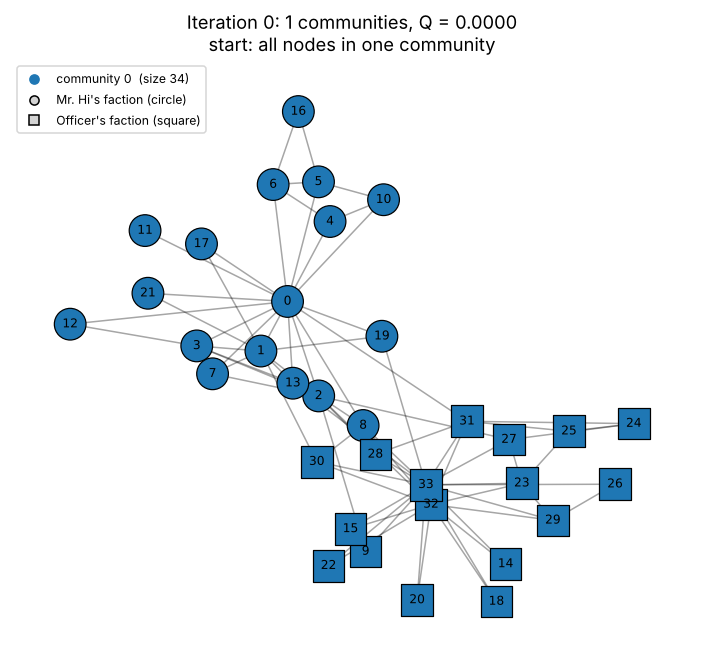

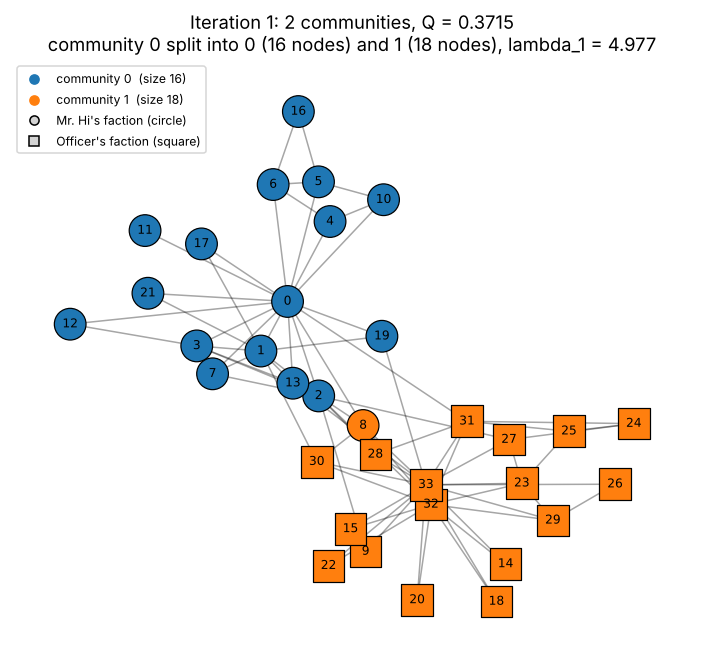

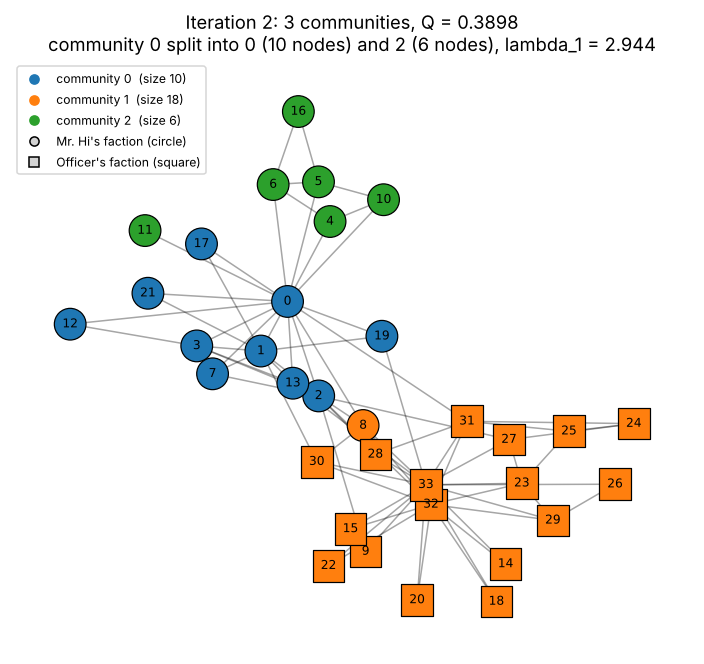

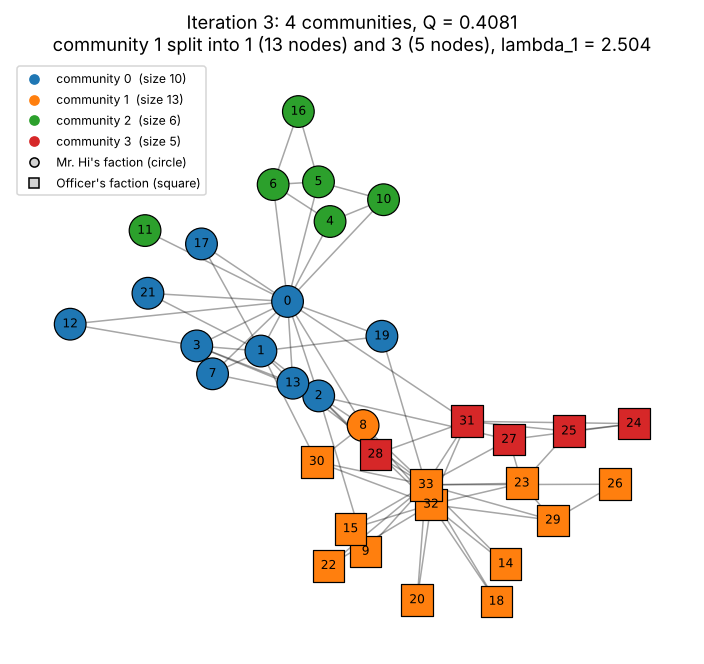

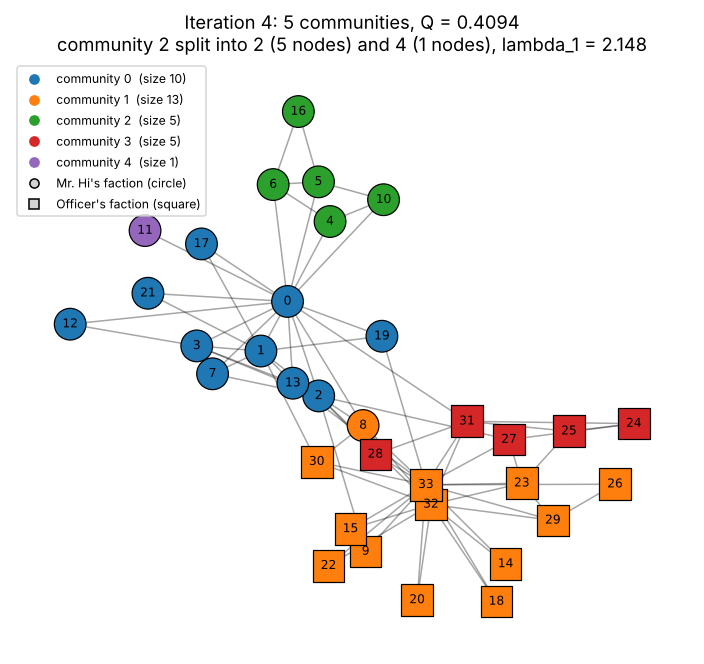

In [8]:
for s in snapshots:
    labels = s["labels"]
    if s["split"] is None:
        subtitle = "start: all nodes in one community"
    else:
        sp = s["split"]
        subtitle = (f"community {sp['parent']} split into {sp['parent']} ({sp['n_plus']} nodes) and "
                    f"{sp['child']} ({sp['n_minus']} nodes), lambda_1 = {sp['lam']:.3f}")
    fig, ax = plt.subplots(figsize=(8, 7))
    draw_partition(labels, f"Iteration {s['iteration']}: {len(np.unique(labels))} communities, Q = {s['Q']:.4f}\n{subtitle}", ax)
    plt.savefig(f"assets/iteration_{s['iteration']}.png", bbox_inches="tight")
    plt.show()

## 6. Node metrics after every split

After each iteration we compute, **for every node**, four NetworkX metrics:

| metric | NetworkX function |
|---|---|
| degree centrality | `nx.degree_centrality` |
| betweenness centrality | `nx.betweenness_centrality` |
| closeness centrality | `nx.closeness_centrality` |
| clustering coefficient | `nx.clustering` |

**How the metrics are defined at each iteration.** On the full graph $G$ these four numbers never change, so they could not "evolve" across iterations. We therefore compute them **inside the community each node currently belongs to**: for every community we take the induced subgraph $G[C]$ and call the NetworkX function on it. This shows how a node's role looks once the network is viewed community by community.
- **Iteration 0** has a single community, so the values are the ordinary whole-graph metrics.
- A community of **one node** has no neighbours; all four metrics are set to 0 (NetworkX returns 1.0 for the degree centrality of a one-node graph, which would be misleading).
- If an induced subgraph is not connected, NetworkX's default closeness (Wasserman–Faust scaling) is used; nodes in small fragments get proportionally lower closeness.

Results are stored in `metric_history[metric][iteration]`, an array with one value per node.

In [9]:
METRICS = {
    "degree":     ("Degree centrality",       nx.degree_centrality),
    "betweenness":("Betweenness centrality",  nx.betweenness_centrality),
    "closeness":  ("Closeness centrality",    nx.closeness_centrality),
    "clustering": ("Clustering coefficient",  nx.clustering),
}

def community_metrics(labels):
    '''Compute each metric for every node inside its own community (induced subgraph).'''
    out = {name: np.zeros(n) for name in METRICS}
    for c in np.unique(labels):
        members = [int(v) for v in np.where(labels == c)[0]]
        if len(members) < 2:                       # singleton: metrics set to 0
            continue
        H = G.subgraph(members)
        for name, (_, func) in METRICS.items():
            values = func(H)
            for v in members:
                out[name][v] = values[v]
    return out

metric_history = {name: {} for name in METRICS}    # metric_history[metric][iteration] -> array of n values
for s in snapshots:
    res = community_metrics(s["labels"])
    for name in METRICS:
        metric_history[name][s["iteration"]] = res[name]

# Sanity check: iteration 0 must equal the plain whole-graph NetworkX values
for name, (_, func) in METRICS.items():
    whole = np.array([func(G)[v] for v in nodes])
    assert np.allclose(metric_history[name][0], whole), name
print("Metrics stored for iterations", sorted(metric_history["degree"]), "- iteration 0 matches the whole-graph values.")

Metrics stored for iterations [0, 1, 2, 3, 4] - iteration 0 matches the whole-graph values.


## 7. Evolution of each metric across iterations
For each metric: **left**, every node's trajectory (grey) with the six nodes of highest average value highlighted and labelled; **right**, a heatmap with *all 34 nodes* (rows) against iterations (columns), so that every node can be read off by its ID.

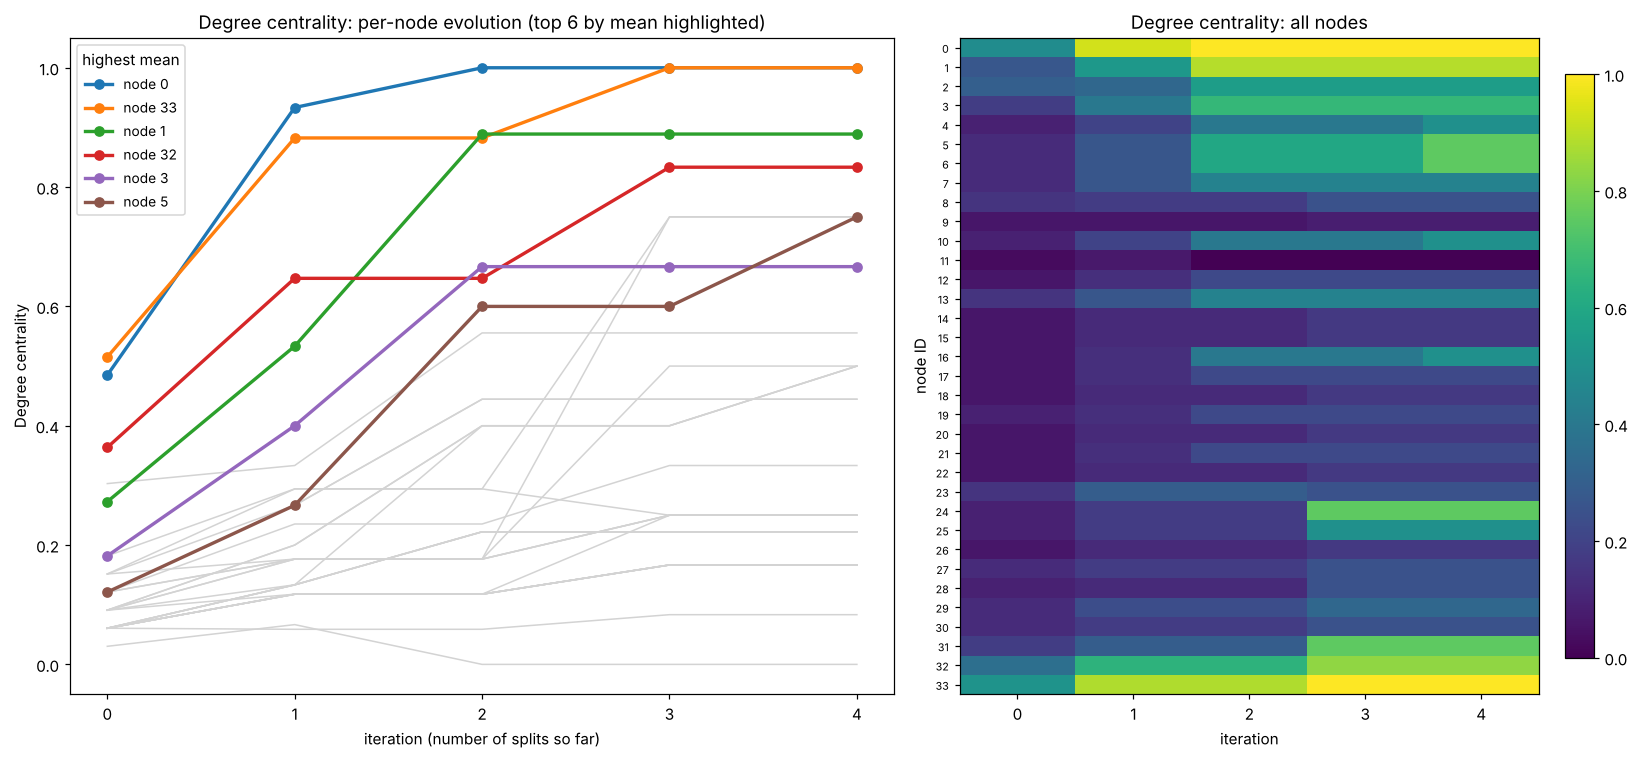

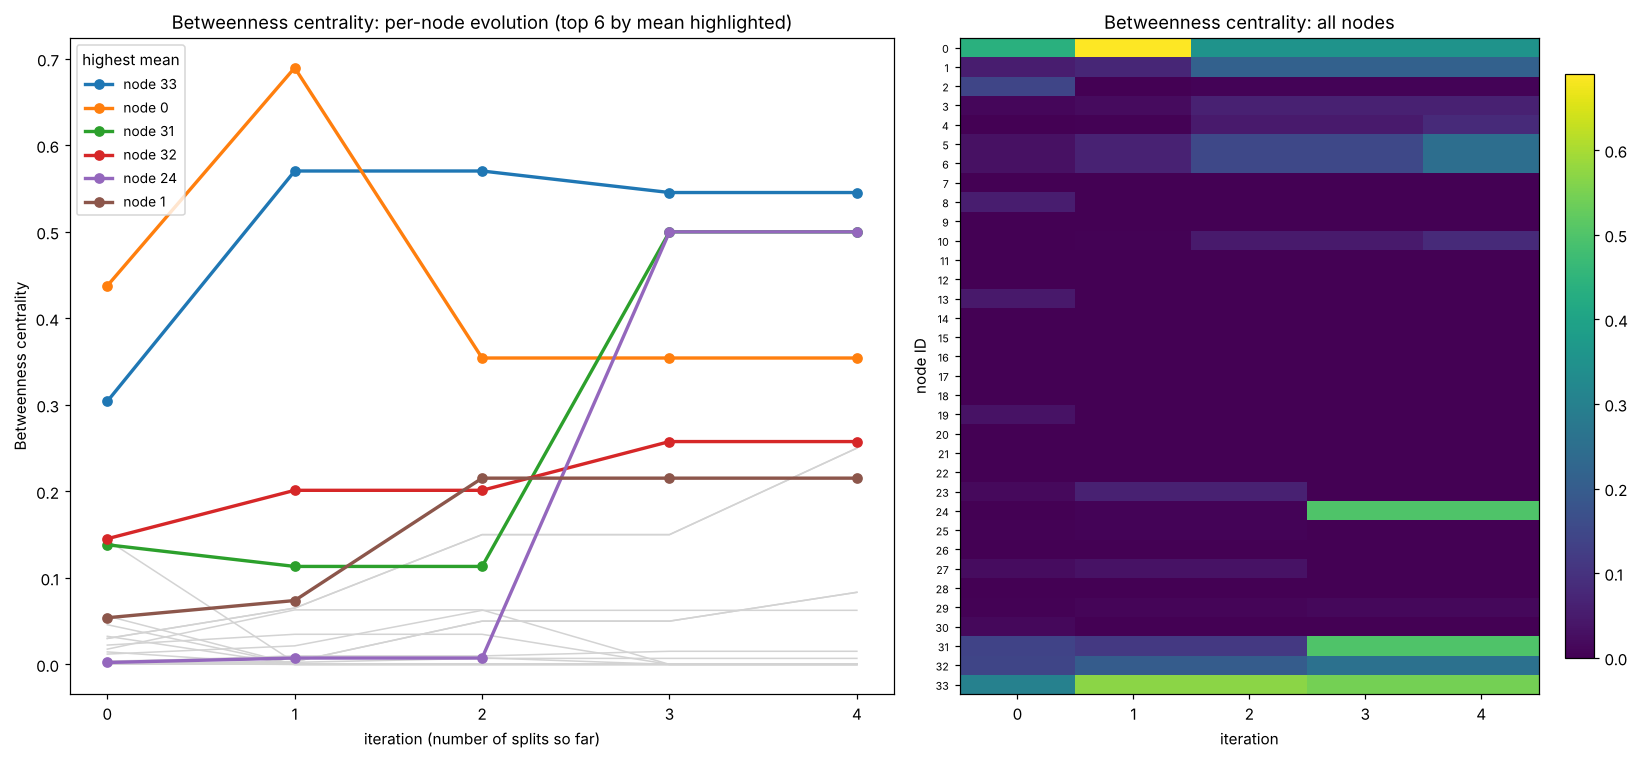

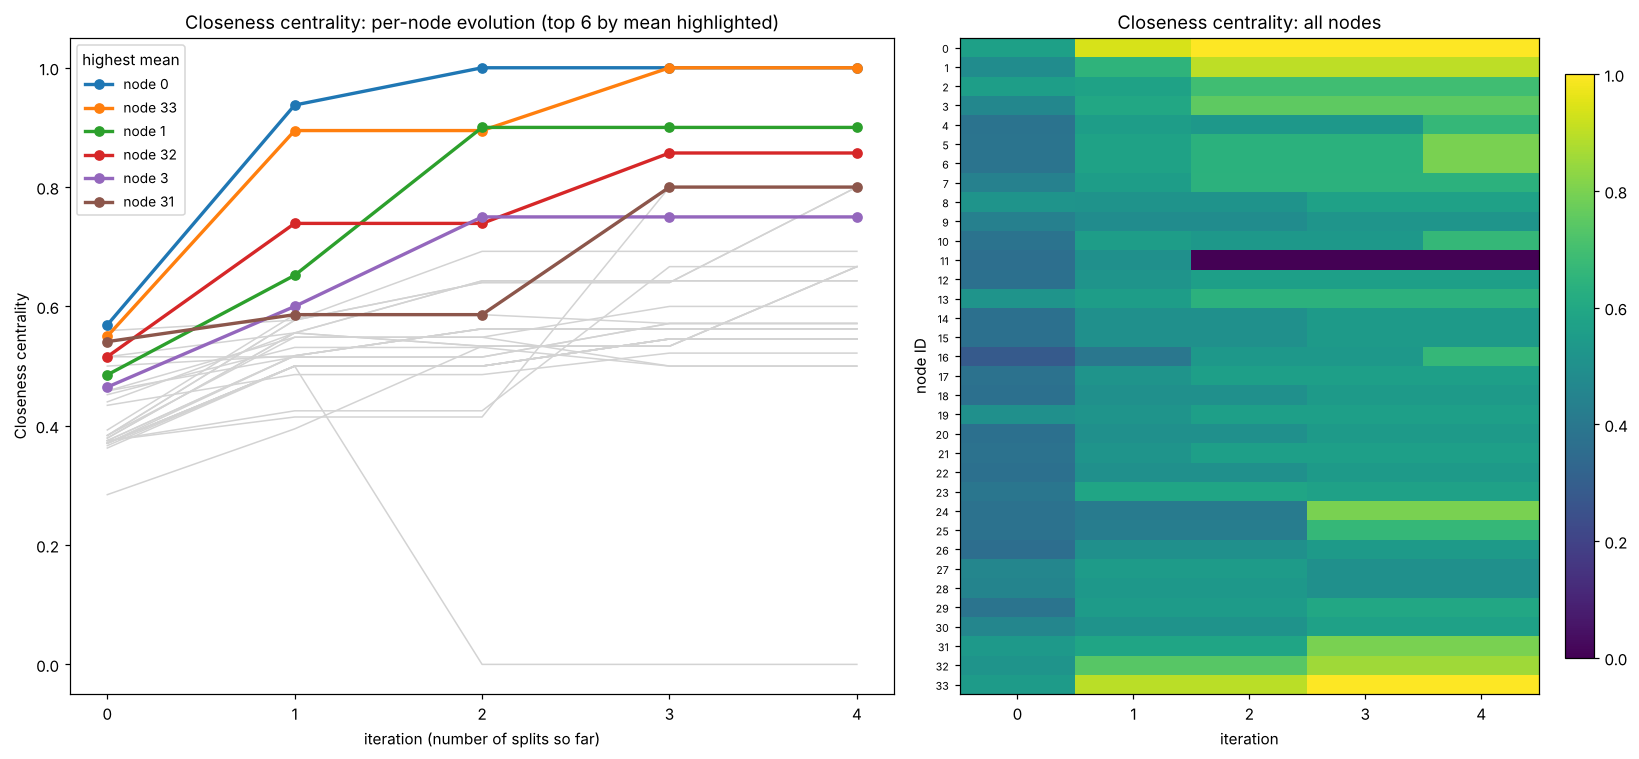

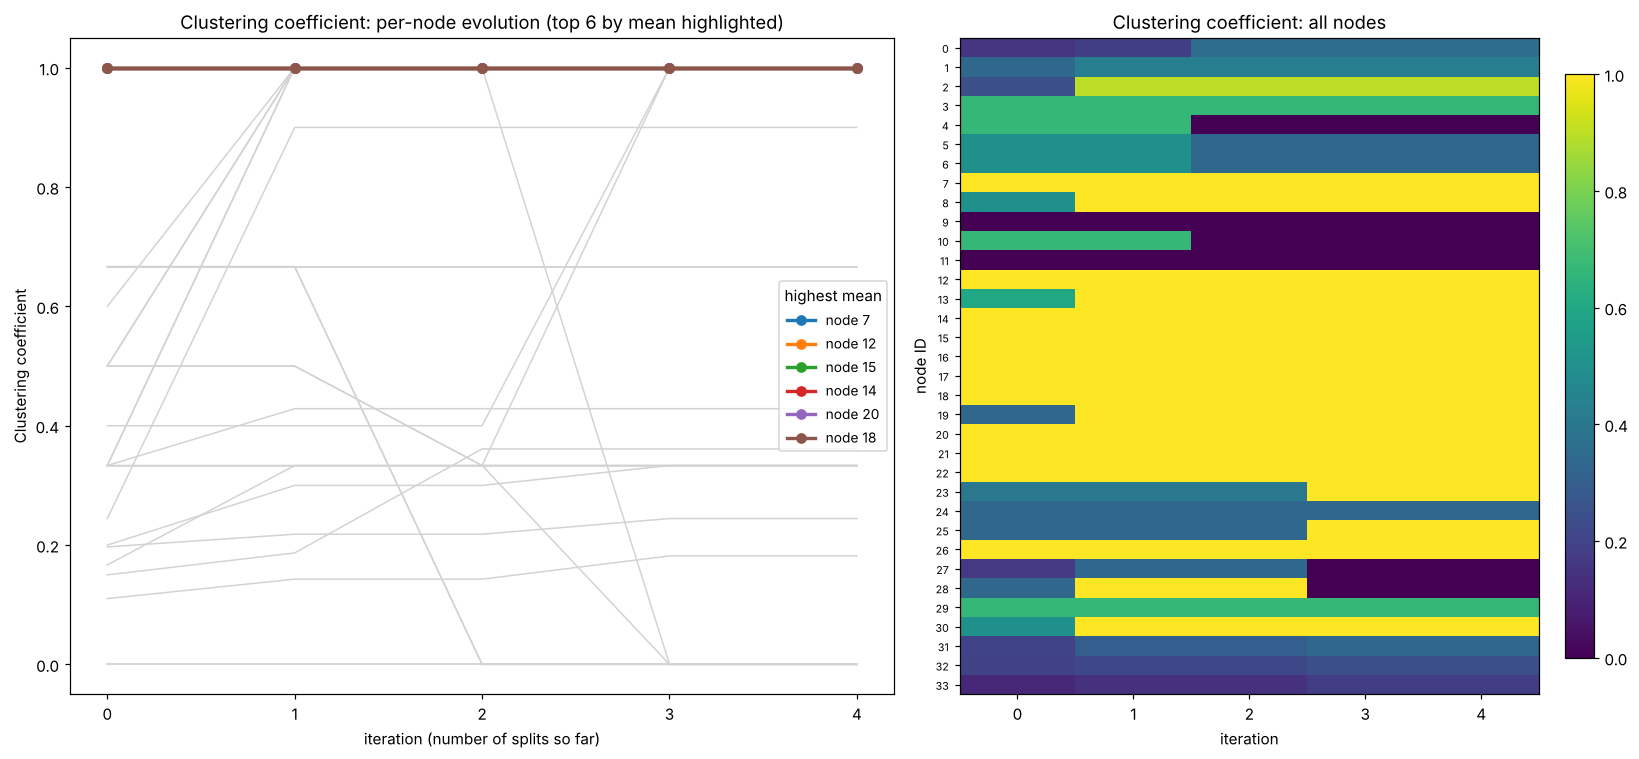

In [10]:
iters = sorted(metric_history["degree"])

def plot_metric(name):
    title, _ = METRICS[name]
    M = np.array([metric_history[name][it] for it in iters])        # shape (iterations, nodes)
    top = np.argsort(-M.mean(axis=0))[:6]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.3, 1]})
    for v in range(n):
        ax1.plot(iters, M[:, v], color="lightgray", lw=1, zorder=1)
    for rank, v in enumerate(top):
        ax1.plot(iters, M[:, v], marker="o", lw=2.2, color=PALETTE[rank], label=f"node {v}", zorder=3)
    ax1.set_xticks(iters); ax1.set_xlabel("iteration (number of splits so far)"); ax1.set_ylabel(title)
    ax1.set_title(f"{title}: per-node evolution (top 6 by mean highlighted)")
    ax1.legend(title="highest mean", fontsize=9)
    im = ax2.imshow(M.T, aspect="auto", cmap="viridis")
    ax2.set_xticks(range(len(iters))); ax2.set_xticklabels(iters)
    ax2.set_yticks(range(n)); ax2.set_yticklabels(range(n), fontsize=7)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node ID"); ax2.set_title(f"{title}: all nodes")
    fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(f"assets/metric_{name}.png", bbox_inches="tight")
    plt.show()

for name in METRICS:
    plot_metric(name)

## 8. Discussion
The cell below extracts the numbers that the discussion refers to: the nodes that stay on top of each metric, and how the average metric value moves as communities shrink.

In [11]:
TOPK = 5

def top_set(values, k):
    '''Indices of the k largest values, INCLUDING all nodes tied with the k-th value.'''
    thr = np.sort(values)[::-1][k - 1]
    return set(np.where(values >= thr - 1e-12)[0].tolist())

print(f"Nodes that are in the top-{TOPK} (ties included) at EVERY iteration, and top-{TOPK} by mean value\n")
for name, (title, _) in METRICS.items():
    M = np.array([metric_history[name][it] for it in iters])
    always = set(range(n))
    for row in M:
        always &= top_set(row, TOPK)
    top_mean = np.argsort(-M.mean(axis=0), kind="stable")[:TOPK].tolist()
    print(f"{title:24s} always in top-{TOPK}: {sorted(int(v) for v in always)}")
    print(f"{'':24s} top-{TOPK} by mean over iterations: {top_mean}")

print("\nSelected node trajectories (iterations 0 -> 4)")
for name, nodes_of_interest in [("degree", [0, 33, 32]), ("betweenness", [0, 33, 2, 8, 24, 31]),
                                ("closeness", [0, 33, 11]), ("clustering", [0, 33, 7])]:
    for v in nodes_of_interest:
        vals = " ".join(f"{metric_history[name][it][v]:.3f}" for it in iters)
        print(f"  {METRICS[name][0]:24s} node {v:>2}: {vals}")

print("\nAverage metric value over all nodes, per iteration")
print(f"{'iteration':>10} {'#comm':>6} " + " ".join(f"{METRICS[nm][0][:12]:>13}" for nm in METRICS))
for it, s in zip(iters, snapshots):
    row = " ".join(f"{metric_history[nm][it].mean():>13.3f}" for nm in METRICS)
    print(f"{it:>10} {len(np.unique(s['labels'])):>6} {row}")

print("\nHighest-betweenness node inside each final community (value inside its community):")
for c in np.unique(final_labels):
    members = np.where(final_labels == c)[0]
    b = metric_history["betweenness"][iters[-1]][members]
    print(f"  community {c} {members.tolist()}  ->  node {int(members[np.argmax(b)])} ({b.max():.3f})")

Nodes that are in the top-5 (ties included) at EVERY iteration, and top-5 by mean value

Degree centrality        always in top-5: [0, 1, 32, 33]
                         top-5 by mean over iterations: [0, 33, 1, 32, 3]
Betweenness centrality   always in top-5: [0, 32, 33]
                         top-5 by mean over iterations: [33, 0, 31, 32, 24]
Closeness centrality     always in top-5: [0, 32, 33]
                         top-5 by mean over iterations: [0, 33, 1, 32, 3]
Clustering coefficient   always in top-5: [7, 12, 14, 15, 16, 17, 18, 20, 21, 22, 26]
                         top-5 by mean over iterations: [7, 12, 14, 15, 16]

Selected node trajectories (iterations 0 -> 4)
  Degree centrality        node  0: 0.485 0.933 1.000 1.000 1.000
  Degree centrality        node 33: 0.515 0.882 0.882 1.000 1.000
  Degree centrality        node 32: 0.364 0.647 0.647 0.833 0.833
  Betweenness centrality   node  0: 0.438 0.690 0.354 0.354 0.354
  Betweenness centrality   node 33: 0.304 0.570 

### Which nodes stay central across splits?
**Nodes 0 and 33, the instructor "Mr. Hi" and the club president, are the consistent leaders**, with node 32 close behind. Node 0 and node 33 are the two highest-average nodes for degree and closeness centrality. Nodes 0, 32 and 33 are in the top 5 for degree, betweenness *and* closeness at every iteration (node 1 joins them for degree). Inside their own final communities, node 0 and node 33 are also the highest-betweenness nodes (0.354 and 0.545). Their degree and closeness centrality reach 1.0 once their communities shrink: from iteration 2 for node 0 and iteration 3 for node 33, each is directly connected to every other member of its group. So the two figures at the centre of the real conflict are also the hubs around which the algorithm's communities form.

### How community structure influences the metrics
- **Metrics are relative to the community, not absolute.** Degree and closeness are normalised by the community size, so the average values rise as the communities shrink (mean degree centrality 0.139 → 0.423, mean closeness 0.426 → 0.639 from iteration 0 to 4). This reflects the smaller reference group, not nodes becoming more important.
- **Betweenness measures bridging, and bridges disappear when communities separate.** Node 2 and node 8 have ties across the two factions. Once the first split removes those ties, their betweenness collapses (node 2: 0.144 → 0.002; node 8: 0.056 → 0). Conversely, nodes 24 and 31 gain betweenness (0.002 → 0.500 and 0.113 → 0.500) when they become the connectors inside the small community {24, 25, 27, 28, 31}.
- **Clustering behaves differently from the centralities.** The hubs have *low* clustering (node 0: 0.15 → 0.36, node 33: 0.11 → 0.18) because their many neighbours are mostly not connected to each other, whereas eleven peripheral nodes (7, 12, 14, 15, 16, 17, 18, 20, 21, 22, 26) have clustering 1.0 at every iteration: all of their neighbours are mutual friends and sit in the same community, so splitting never changes their value. Highly central does not mean highly clustered.
- **Mistakes of the partition show up in the metrics.** Node 11 is a leaf attached only to node 0, but the spectral split places it in a different community from node 0 (iteration 2). Inside its new community it has no neighbours at all, so all its metrics drop to 0 and it is later split off as a singleton at iteration 4. This is a limitation of rounding the leading eigenvector by sign with the handout's restricted matrix; the final modularity is still 0.409, higher than NetworkX's greedy result (0.381).

### Takeaways
The very first spectral split assigns 33 of the 34 members to the same side as in the real split (only node 8 differs) and its modularity (0.3715) is even higher than that of the real split (0.3582), so the friendship structure recorded *before* the fission already contained the fault line. Further splits refine the two factions into smaller friend groups; each group is organised around a few brokers, and the node metrics show who they are.

## 9. Sanity checks
1. Our own modularity formula must agree with NetworkX's implementation for the final partition.
2. How close is the first split (a plain two-way spectral bisection) to the real split of the club?
3. How does the final multi-community result compare with NetworkX's built-in greedy modularity optimizer?

In [12]:
# 1) our modularity vs NetworkX
final_comms = [set(np.where(final_labels == c)[0].tolist()) for c in np.unique(final_labels)]
Q_ours = modularity(B, final_labels, m)
Q_nx = nx_community.modularity(G, final_comms, weight=None)
print(f"Final partition: Q (ours) = {Q_ours:.6f}   Q (NetworkX) = {Q_nx:.6f}   equal: {np.isclose(Q_ours, Q_nx)}")

# 2) first split vs ground truth
first = snapshots[1]["labels"]
pred_hi = first == first[0]                       # side that contains node 0 (Mr. Hi)
true_hi = club == "Mr. Hi"
wrong = np.where(pred_hi != true_hi)[0].tolist()
truth_labels = (club == "Officer").astype(int)
print(f"\nFirst spectral split: {int(pred_hi.sum())} / {int((~pred_hi).sum())} nodes, Q = {snapshots[1]['Q']:.4f}")
print(f"Ground-truth split:   {int(true_hi.sum())} / {int((~true_hi).sum())} nodes, Q = {modularity(B, truth_labels, m):.4f}")
print(f"Nodes on the 'wrong' side compared with the real split: {wrong}  -> {n - len(wrong)}/{n} correct ({(n - len(wrong)) / n:.1%})")

# 3) comparison with NetworkX's greedy modularity maximisation (for reference only)
greedy = nx_community.greedy_modularity_communities(G, weight=None)
print(f"\nNetworkX greedy modularity: {len(greedy)} communities, Q = {nx_community.modularity(G, greedy, weight=None):.4f}"
      f"   |   our recursive spectral method: {len(final_comms)} communities, Q = {Q_ours:.4f}")

Final partition: Q (ours) = 0.409435   Q (NetworkX) = 0.409435   equal: True

First spectral split: 16 / 18 nodes, Q = 0.3715
Ground-truth split:   17 / 17 nodes, Q = 0.3582
Nodes on the 'wrong' side compared with the real split: [8]  -> 33/34 correct (97.1%)

NetworkX greedy modularity: 3 communities, Q = 0.3807   |   our recursive spectral method: 5 communities, Q = 0.4094
